# Kunz et al. 2025, inner speech in motor cortex: the neuralset `Study`

[`study.py`](study.py) turns the 41 source files into one standardized **events table**. **One recorded block is one timeline (243 in total)**, because the neural activity between blocks was not recorded. Each timeline emits:

- two neural streams over the whole block, **`SpikeCounts`** (`threshold_crossings`) and **`BandPower`** (`spike_band_power`), `(n_channels, n_bins)` at the file's bin rate, read lazily through the package [`NeuralFeatureExtractor`](../../extractors.py).
- per active trial, a **`Stimulus`** over the delay period, a one-bin go **`Stimulus`**, and the cued unit over the go period: a `Word`, a `Sentence` or an `Action`.
- per passive listening or reading trial, the `Word` over its presentation.
- an **`Intertrial`** over every gap before the next trial of the block.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import neuralset as ns
import neuralshed.events  # noqa: F401, registers the custom event types
from neuralshed import viz
from neuralshed.extractors import CharacterEncoder, NeuralFeatureExtractor
from neuralshed.datasets.kunz_2025 import study, utils
from neuralshed.datasets.utils import dataset_dir
from neuralset.events.etypes import Event
from neuralset.events.study import STUDIES
from neuralset.extractors import EventField, LabelEncoder

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# reads ./.env into os.environ
load_dotenv()

root = dataset_dir("kunz_2025") / "data"
s = study.Kunz2025InnerSpeech(path=root)
s.download()
print("Kunz2025InnerSpeech registered:", "Kunz2025InnerSpeech" in STUDIES)

# one block per emission branch: (session, block)
PICKS = {
    "active words, 10 ms": ("t15.2024.04.07_allBehaviors_raw", 12),
    "passive words, 20 ms": ("t12.2023.08.15_allBehaviors_raw", 4),
    "passive words, T16 go stub": ("t16.2024.03.04_allBehaviors_raw", 19),
    "interleaved words, copied band power": (
        "t12.2024.04.11_interleavedVerbalBehaviors_raw",
        5,
    ),
    "sentences, closed loop, 25 ms": (
        "t12.2024.12.19_chittychittybangbang_50words_eval",
        5,
    ),
    "sentences, closed loop, 33 ms": ("t16.2024.04.29_imagined_50words_eval", 14),
    "counting, 10 ms": ("t15.2024.12.15_conjunctive_counting", 6),
    "sequence, uint8-tagged, 20 ms": (
        "t12.2023.05.16_binnedTX_spikePow_20ms_joystickSeq",
        1,
    ),
    "sequence, verbal memory, 40 ms inferred": (
        "t16.2024.07.17_binnedTX_spikePow_20ms_verbal",
        1,
    ),
}

TRIAL_COLUMNS = [
    "type",
    "start",
    "duration",
    "period",
    "stimulus_kind",
    "action_kind",
    "code",
    "text",
    "description",
    "task_condition",
    "behavior",
    "modality",
    "keyword",
]
NEURAL_TYPES = ["SpikeCounts", "BandPower"]


def block_events(events, pick):
    # every row of one picked block
    session, block = PICKS[pick]
    return events[(events.session == session) & (events.block == block)]


def first_trial(events, pick, skip=0, query=None):
    # the rows of one trial of a picked block, optionally the first trial matching a query
    rows = block_events(events, pick)
    rows = rows[~rows.type.isin(NEURAL_TYPES)]
    candidates = rows if query is None else rows.query(query)
    trial_id = sorted(candidates.trial_id.unique())[skip]
    columns = [c for c in TRIAL_COLUMNS if c in rows.columns]
    return rows.loc[rows.trial_id == trial_id, columns].dropna(axis=1, how="all")


def as_events(rows):
    return [Event.from_dict(row.to_dict()) for _, row in rows.iterrows()]


def read_stream(events, pick, event_type, target_unit, start=1.0, duration=2.0):
    # a window of one neural row of a block, at the block's own rate (None without a valid row)
    rows = block_events(events, pick)
    rows = rows[(rows.type == event_type) & rows.valid]
    if rows.empty:
        return None
    frequency = float(rows.frequency.iloc[0])
    extractor = NeuralFeatureExtractor(
        target_unit=target_unit,
        event_types=(event_type,),
        frequency=frequency,
    )
    return extractor(as_events(rows), start=start, duration=duration).numpy()

Kunz2025InnerSpeech registered: True


## 1. Timelines, one per recorded block

`iter_timelines` yields one dict per block. Its keys identify the timeline and are broadcast to every event row: `subject`, `session` (the file stem), `block`, `date`, `post_implant_day`, `experiment`, `vocab`, `loop_type`, `original_split` and `mean_subtracted`.

In [2]:
timelines = pd.DataFrame(s.iter_timelines())
print("timelines:", len(timelines), "| sessions:", timelines.session.nunique())

overview = timelines.groupby("experiment").agg(
    n_timelines=("path", "size"),
    subjects=("subject", lambda x: "|".join(sorted(set(x)))),
)
display(overview)
timelines.drop(columns="path").head(3)

timelines: 243 | sessions: 41


,n_timelines,subjects
experiment,,
chittychittybangbang,17,T12
conjunctiveCounting,2,T15|T16
interleavedVerbalBehaviors,29,T12|T15|T16|T17
isolatedVerbalBehaviors,70,T12|T15|T16|T17
sentenceData,44,T12|T15|T16
seqRecallSpeech,5,T12|T16
seqRecallUninstructed3ElementArrow,32,T12|T16
seqRecallUninstructed3ElementLines,21,T12|T16
seqRecallUninstructedSingleArrow,3,T12


,subject,session,date,post_implant_day,block,experiment,vocab,loop_type,original_split,mean_subtracted
0,T12,t12.2024.12.06_chittychittybangbang_50words,2024-12-06,982,1,chittychittybangbang,50w,open,train,False
1,T12,t12.2024.12.06_chittychittybangbang_50words,2024-12-06,982,2,chittychittybangbang,50w,open,train,False
2,T12,t12.2024.12.06_chittychittybangbang_50words,2024-12-06,982,3,chittychittybangbang,50w,open,train,False


## 2. Load one block per branch

Timelines are selected with a `query` over those attributes. The nine blocks below cover every event family, the five bin sizes, both normalization regimes and the source quirks. `timeline_index` also works, but it counts in subject-sorted order, so attribute filters are easier to read.

In [3]:
clauses = [
    f"(session == '{session}' and block == {block})"
    for session, block in PICKS.values()
]
events = study.Kunz2025InnerSpeech(path=root, query=" or ".join(clauses)).run()

print("events:", events.shape, "| timelines:", events.timeline.nunique())
pd.crosstab(events.session, events.type)

events: (1410, 52) | timelines: 9


type,Action,BandPower,Intertrial,Sentence,SpikeCounts,Stimulus,Word
session,,,,,,,
t12.2023.05.16_binnedTX_spikePow_20ms_joystickSeq,32,1,0,0,1,64,0
t12.2023.08.15_allBehaviors_raw,7,1,56,0,1,0,49
t12.2024.04.11_interleavedVerbalBehaviors_raw,2,1,14,0,1,60,42
t12.2024.12.19_chittychittybangbang_50words_eval,0,1,39,40,1,80,0
t15.2024.04.07_allBehaviors_raw,10,1,79,0,1,160,70
t15.2024.12.15_conjunctive_counting,40,1,39,0,1,40,0
t16.2024.03.04_allBehaviors_raw,7,1,55,0,1,0,49
t16.2024.04.29_imagined_50words_eval,0,1,49,50,1,100,0
t16.2024.07.17_binnedTX_spikePow_20ms_verbal,40,1,39,0,1,80,0


## 3. The rows of a trial

Every trial row carries `trial_id`, `period` (`delay`, `go`, `presentation` or `intertrial`), `cue_text` and the conventions of the corpus: `stimulus_kind` or `action_kind`, `task_condition` and `modality`.

**An active word trial**: the cue over the delay (`word_cue`, with the word index in `code`), the go marker, the `Word` over the go period, then the `Intertrial` before the next trial.

In [4]:
first_trial(events, "active words, 10 ms")

,type,start,duration,period,stimulus_kind,code,text,description,task_condition,behavior,modality
616,Stimulus,0.00,1.49,delay,word_cue,6.0,NaN,though-attempted,na,NaN,visual
617,Word,1.49,3.01,go,NaN,NaN,though,NaN,attempted,attempted,read
618,Stimulus,1.49,0.01,go,speech_go_cue,-100.0,NaN,go cue,na,NaN,visual
619,Intertrial,4.50,0.50,intertrial,NaN,NaN,NaN,intertrial interval,na,NaN,NaN


**A passive word trial** has no delay and no go cue. The word spans the source's delay epoch, where it was played or shown (`period="presentation"`), and the `Intertrial` runs from the source's go epoch to the next trial.

In [5]:
first_trial(events, "passive words, 20 ms", skip=1)

,type,start,duration,period,text,description,task_condition,behavior,modality
285,Word,12.76,1.52,presentation,ban,NaN,listening,listening,heard
286,Intertrial,14.28,1.50,intertrial,NaN,intertrial interval,na,NaN,NaN


**A T12 interleaved listening trial.** The word was played at delay onset, so it spans the source's delay epoch as a presentation, with no cue `Stimulus`, and the source's go epoch is the `Intertrial`. The interleaved listening trials of T15, T16 and T17 are go-aligned by the authors and emitted as active trials.

In [6]:
first_trial(
    events,
    "interleaved words, copied band power",
    query="behavior == 'listening'",
)

,type,start,duration,period,text,description,task_condition,behavior,modality
175,Word,25.3,1.8,presentation,feel,NaN,listening,listening,heard
176,Intertrial,27.1,3.0,intertrial,NaN,intertrial interval,na,NaN,NaN


**A T16 passive trial.** T16's isolated passive blocks store a one-bin go stub instead of the 1.5 s intertrial interval, so the `Intertrial` runs from that stub to the next trial's onset, and a block's last passive trial has none.

In [7]:
first_trial(events, "passive words, T16 go stub")

,type,start,duration,period,text,description,task_condition,behavior,modality
937,Word,0.00,1.49,presentation,were,NaN,listening,listening,heard
938,Intertrial,1.49,1.50,intertrial,NaN,intertrial interval,na,NaN,NaN


**A keyword sentence trial.** On a keyword trial, `text` starts with the imagined unlock keyword `chittychittybangbang` in place of the cue's `*`, and `keyword` marks it. `behavior` names the inner-speech strategy.

In [8]:
first_trial(events, "sentences, closed loop, 25 ms", query="keyword == True")

,type,start,duration,period,stimulus_kind,code,text,description,task_condition,behavior,modality,keyword
22,Stimulus,83.975,5.000,delay,sentence_cue,-100.0,NaN,* Do you need help?,na,NaN,visual,NaN
23,Sentence,88.975,18.450,go,NaN,NaN,chittychittybangbang Do you need help?,NaN,imagined,imagined_motor,imagined,True
24,Stimulus,88.975,0.025,go,speech_go_cue,-100.0,NaN,go cue,na,NaN,visual,NaN
25,Intertrial,107.425,1.425,intertrial,NaN,NaN,NaN,intertrial interval,na,NaN,NaN,NaN


**A counting trial** is self-paced: the grid `Stimulus` lasts as long as the silent count, there is no go marker, and the `Action` is the spoken report with `num_targets`.

In [9]:
first_trial(events, "counting, 10 ms")

,type,start,duration,period,stimulus_kind,action_kind,code,description,task_condition,modality
495,Stimulus,0.00,60.15,delay,counting_grid,NaN,20.0,count 20,na,visual
496,Action,60.15,6.07,go,NaN,speech,20.0,count 20,attempted,NaN
497,Intertrial,66.22,0.99,intertrial,NaN,NaN,NaN,intertrial interval,na,NaN


**A sequence trial.** The delay `Stimulus` is `imagined` under the verbal-memory strategy (the participant rehearses the sequence in inner speech) and `na` otherwise. The `Action` is the attempted movement, with the cued sequence in `description`. On these T16 files the periods are the Table S4 task periods.

In [10]:
first_trial(events, "sequence, verbal memory, 40 ms inferred")

,type,start,duration,period,stimulus_kind,action_kind,code,description,task_condition,modality
1251,Stimulus,0.0,2.00,delay,movement_cue,NaN,3.0,↑ → ↑,imagined,visual
1252,Action,2.0,4.00,go,NaN,drawing,3.0,↑ → ↑,attempted,NaN
1253,Stimulus,2.0,0.04,go,movement_go_cue,NaN,-100.0,go cue,na,visual
1254,Intertrial,6.0,1.00,intertrial,NaN,NaN,NaN,intertrial interval,na,NaN


## 4. The neural rows

One `SpikeCounts` and one `BandPower` row per block, `SpikeCounts` first. `frequency` follows the file's bin size, `normalization` says whether the source shipped raw or block-wise mean-subtracted features, and `processing` records the chain, including the `int8` reinterpretation and the inferred 40 ms bins.

In [11]:
neural = events[events.type.isin(NEURAL_TYPES)]
columns = [
    "session",
    "block",
    "type",
    "frequency",
    "n_features",
    "unit",
    "normalization",
    "threshold",
    "valid",
    "duration",
]
display(neural[columns])

for text in neural.loc[neural.type == "SpikeCounts", "processing"].unique():
    print("-", text)

,session,block,type,frequency,n_features,unit,normalization,threshold,valid,duration
0,t12.2024.12.19_chittychittybangbang_50words_eval,5,SpikeCounts,40.00000,256,counts/bin,raw,-4.5 x SD,True,1006.425
1,t12.2024.12.19_chittychittybangbang_50words_eval,5,BandPower,40.00000,256,uV^2,raw,NaN,True,1006.425
161,t12.2024.04.11_interleavedVerbalBehaviors_raw,5,SpikeCounts,50.00000,128,counts/bin,raw,-4.5 x SD,True,220.780
162,t12.2024.04.11_interleavedVerbalBehaviors_raw,5,BandPower,50.00000,128,uV^2,raw,NaN,False,220.780
281,t12.2023.08.15_allBehaviors_raw,4,SpikeCounts,50.00000,128,counts/bin,raw,-4.5 x SD,True,180.920
282,t12.2023.08.15_allBehaviors_raw,4,BandPower,50.00000,128,uV^2,raw,NaN,True,180.920
395,t12.2023.05.16_binnedTX_spikePow_20ms_joystickSeq,1,SpikeCounts,50.00000,256,counts/bin,mean_subtracted,-4.5 x SD,True,238.880
396,t12.2023.05.16_binnedTX_spikePow_20ms_joystickSeq,1,BandPower,50.00000,256,uV^2,mean_subtracted,NaN,True,238.880
493,t15.2024.12.15_conjunctive_counting,6,SpikeCounts,100.00000,256,counts/bin,raw,-4.5 x SD,True,2458.380
494,t15.2024.12.15_conjunctive_counting,6,BandPower,100.00000,256,uV^2,raw,NaN,True,2458.380


- 250 Hz non-causal high-pass (4 ms delay); linear regression referencing fit on the session's initial diagnostic or rest block
- 250 Hz non-causal high-pass (4 ms delay); linear regression referencing fit on the session's initial diagnostic or rest block; mean subtracted per block; uint8 class tag reinterpreted as int8
- 250 Hz non-causal high-pass (1 ms delay); linear regression referencing fit on the session's initial diagnostic or rest block
- 250 Hz non-causal high-pass (4 ms delay); linear regression referencing fit on the session's initial diagnostic or rest block; mean subtracted per block; 40 ms bins inferred, the file stores binSize=20


`valid=False` marks rows whose released data are bad. Here it is the `BandPower` of `t12.2024.04.11`, which the source stores as a copy of `binnedTX`. Filter on `valid` before reading.

In [12]:
display(events.loc[~events.valid, ["session", "block", "type", "valid_description"]])

events = events[events.valid]
print("rows kept:", len(events))

,session,block,type,valid_description
162,t12.2024.04.11_interleavedVerbalBehaviors_raw,5,BandPower,spikePow is stored as uint8 and is a byte-iden...


rows kept: 1409


### Browse the events interactively

`viz.explore_events` opens a live-kernel dashboard over the same table, one lane per event type, one timeline at a time. The neural rows are read on demand. The timeline picker lists the nine blocks loaded above by their attributes.

In [13]:
explorer = viz.explore_events(events=events)
explorer

## 5. Read the neural streams through the extractor

`NeuralFeatureExtractor` reads a window of a dense row at the requested `frequency`. `target_unit="native"` returns the stored values (counts per bin, or mean-subtracted counts), `target_unit="Hz"` divides counts by the bin size. Each block is read at its own rate. `BandPower` is read natively: µV² in the raw families, and centred per block in the mean-subtracted ones, so a short window of those sits near zero rather than at it. The copied band power of `t12.2024.04.11` has no valid row, so its power column is empty.

In [14]:
rows = []
for pick in PICKS:
    counts = read_stream(events, pick, "SpikeCounts", "native")
    rates = read_stream(events, pick, "SpikeCounts", "Hz")
    power = read_stream(events, pick, "BandPower", "native")
    block = block_events(events, pick)
    rows.append(
        {
            "block": pick,
            "frequency": float(block.frequency.dropna().iloc[0]),
            "normalization": block.normalization.dropna().iloc[0],
            "window shape": counts.shape,
            "counts, native": round(float(counts.mean()), 3),
            "counts, Hz": round(float(rates.mean()), 2),
            "power, native": None if power is None else round(float(power.mean()), 2),
        }
    )
pd.DataFrame(rows)

,block,frequency,normalization,window shape,"counts, native","counts, Hz","power, native"
0,"active words, 10 ms",100.00000,raw,"(256, 200)",0.231,23.12,1258.41
1,"passive words, 20 ms",50.00000,raw,"(128, 100)",1.986,99.31,279.25
2,"passive words, T16 go stub",100.00000,raw,"(256, 200)",0.195,19.46,762.77
3,"interleaved words, copied band power",50.00000,raw,"(128, 100)",0.341,17.04,NaN
4,"sentences, closed loop, 25 ms",40.00000,raw,"(256, 80)",0.377,15.10,106.11
5,"sentences, closed loop, 33 ms",30.30303,raw,"(256, 61)",0.206,6.23,825.66
6,"counting, 10 ms",100.00000,raw,"(256, 200)",0.207,20.65,856.95
7,"sequence, uint8-tagged, 20 ms",50.00000,mean_subtracted,"(256, 100)",0.106,5.31,14.33
8,"sequence, verbal memory, 40 ms inferred",25.00000,mean_subtracted,"(256, 50)",0.012,0.31,31.78


With both types selected, `aggregation="cat"` stacks the two streams along the channel axis in the order of the source, `[binnedTX | spikePow]`.

cat(SpikeCounts, BandPower), first 8 s: (512, 800)


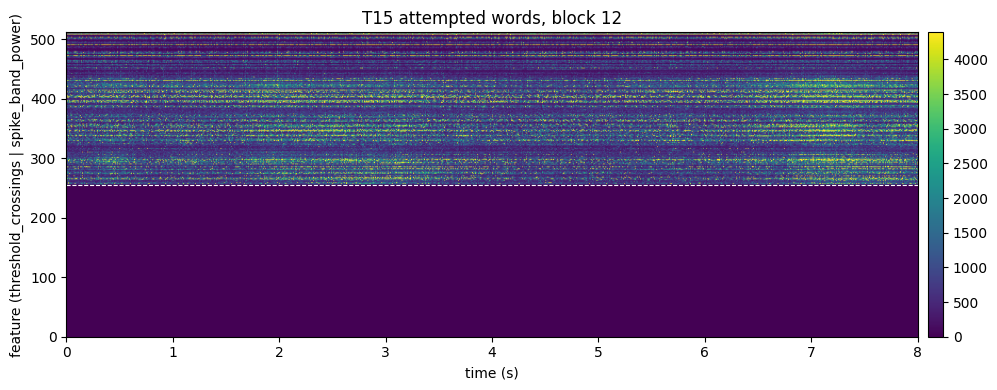

In [15]:
rows = block_events(events, "active words, 10 ms")
rows = rows[rows.type.isin(NEURAL_TYPES)]
extractor = NeuralFeatureExtractor(
    target_unit="native",
    frequency=100.0,
    aggregation="cat",
)
window = extractor(as_events(rows), start=0.0, duration=8.0).numpy()
print("cat(SpikeCounts, BandPower), first 8 s:", window.shape)

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(
    window,
    aspect="auto",
    origin="lower",
    cmap="viridis",
    vmin=np.percentile(window, 2),
    vmax=np.percentile(window, 98),
    extent=[0, 8, 0, window.shape[0]],
)
ax.axhline(window.shape[0] // 2, color="w", lw=0.8, ls="--")
ax.set(
    xlabel="time (s)",
    ylabel="feature (threshold_crossings | spike_band_power)",
    title="T15 attempted words, block 12",
)
fig.colorbar(im, ax=ax, pad=0.01)
plt.tight_layout()
plt.show()

## 6. Targets

Each unit has a target extractor. `LabelEncoder` turns the `text` of the `Word` rows and the `description` of the sequence `Action` rows into class indices. `CharacterEncoder` reads a `Sentence` into character ids for a CTC loss. `EventField` reads the numeric `num_targets` of the counting `Action`.

In [16]:
words = events[events.type == "Word"]
word_encoder = LabelEncoder(
    event_types="Word",
    event_field="text",
    predefined_mapping={word: k for k, word in enumerate(utils.WORDS)},
)
word_events = as_events(words)
word_encoder.prepare(word_events)
print(
    f"Word: {len(words)} rows, e.g. {words.text.iloc[0]!r} -> {word_encoder.get_static(word_events[0]).tolist()}"
)

sentences = events[events.type == "Sentence"]
sentence_encoder = CharacterEncoder()
sentence_events = as_events(sentences)
sentence_encoder.prepare(sentence_events)
print(
    f"Sentence: {len(sentences)} rows, e.g. {sentences.text.iloc[0]!r} -> {sentence_encoder.get_static(sentence_events[0]).tolist()[:12]} ..."
)

sequences = events[
    (events.type == "Action")
    & events.experiment.str.startswith("seqRecall")
    & (events.action_kind != "rest")
]
sequence_encoder = LabelEncoder(event_types="Action", event_field="description")
sequence_events = as_events(sequences)
sequence_encoder.prepare(sequence_events)
print(
    f"Action (sequence): {len(sequences)} rows, {sequence_encoder._n_classes} classes, e.g. {sequences.description.iloc[0]!r} -> {sequence_encoder.get_static(sequence_events[0]).tolist()}"
)

counts = events[
    (events.type == "Action") & (events.experiment == "conjunctiveCounting")
]
count_field = EventField(event_types="Action", event_field="num_targets")
count_events = as_events(counts)
count_field.prepare(count_events)
print(
    f"Action (counting): {len(counts)} rows, e.g. num_targets -> {count_field.get_static(count_events[0]).tolist()}"
)

Word: 210 rows, e.g. 'ban' -> [0]
Sentence: 90 rows, e.g. 'How am I coming up?' -> [10, 17, 25, 1, 3, 15, 1, 11, 1, 5, 17, 15] ...
Action (sequence): 72 rows, 36 classes, e.g. '← ← ↓' -> [3]
Action (counting): 40 rows, e.g. num_targets -> [20.0]


## 7. From events to a batch

A `Segmenter` cuts one window per trigger event and reads every extractor over it. Here the trigger is the `Word` of the T15 attempted-speech block, the window is the first second of the go period, and the batch holds the 512 neural features with the word index as target.

In [17]:
block = block_events(events, "active words, 10 ms")

segmenter = ns.dataloader.Segmenter(
    extractors={
        "input": NeuralFeatureExtractor(
            target_unit="native",
            frequency=100.0,
            aggregation="cat",
        ),
        "target": LabelEncoder(
            event_types="Word",
            event_field="text",
            predefined_mapping={word: k for k, word in enumerate(utils.WORDS)},
            aggregation="trigger",
        ),
    },
    trigger_query="type == 'Word'",
    start=0.0,
    duration=1.0,
)
dataset = segmenter.apply(block)
dataset.prepare()
batch = dataset.load_all()

print("input :", tuple(batch.data["input"].shape), "(trials, features, samples)")
print(
    "target:",
    tuple(batch.data["target"].shape),
    "| trials per word:",
    np.bincount(batch.data["target"].ravel().numpy()).tolist(),
)

input : (70, 512, 100) (trials, features, samples)
target: (70, 1) | trials per word: [10, 10, 10, 10, 10, 10, 10]


## Summary

- **`Kunz2025InnerSpeech`**: 243 timelines, one per recorded block of 41 files, over four participants and 11 task types.
- Each emits `SpikeCounts` and `BandPower` over the whole block (128 or 256 channels, 25-100 Hz) and, per trial, a delay `Stimulus`, a go `Stimulus` and the cued unit (`Word`, `Sentence` or `Action`), and an `Intertrial` over every gap between trials. Passive trials emit the `Word` over its presentation.
- Filter by attribute (`experiment`, `task_condition`, `behavior`, `period`, `loop_type`, `original_split`, `valid`) and select neural or trial rows by event **type**.
- `NeuralFeatureExtractor` reads each stream at the block's own rate, natively or in Hz. `LabelEncoder`, `CharacterEncoder` and `EventField` give the targets.

Next: [`03_model_example.ipynb`](03_model_example.ipynb) decodes the seven cued words per verbal behavior with a block-grouped split.